# Lesson 4.7: Plotly Visualization

**Analyst:** Meron Welderufael
**Date:** 11/08/2026
**Client:** FinFlow (Product Analytics engagement led by Hannah Whitford)
**Notebook purpose:** Produce the visualization deck for Friday's product
leadership review. Single HTML file output with monthly signup trend,
cohort churn pattern, tier comparison, and one supporting chart.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

df = pd.read_csv(
    'finflow-enriched-200k.csv',
    parse_dates=['signup_date', 'last_login_date', 'churn_date']
)

cohort_churn = pd.read_csv(
    'cohort-churn-by-signup-month.csv'
)
print(f"Customer Data: {df.shape}")
print(f"Cohort churn data: {cohort_churn.shape}")

Customer Data: (200000, 22)
Cohort churn data: (25, 4)


## Panel 1: Cohort churn trend.
A line chart of churn_rate_pct by signup_cohort, using the cohort_churn data from Lesson 4.6. Markers on, line color firebrick (a dark red), with a callout annotation on the most recent three cohorts explaining the "less time-at-risk" effect. Title: "Churn rate by signup cohort."

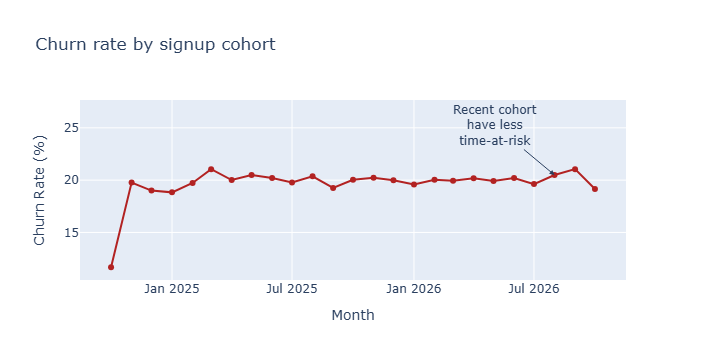

In [2]:
# Make sure signup_cohort is treated as a string for plotting
cohort_churn['signup_cohort_str'] = cohort_churn['signup_cohort'].astype(str)

fig_cohort_churn = px.line(
    cohort_churn,
    x='signup_cohort_str',
    y='churn_rate_pct',
    title='Churn rate by signup cohort',
    labels= {
        'signup_cohort_str': 'Month',
        'churn_rate_pct': 'Churn Rate (%)'
    },
    color_discrete_sequence=['firebrick'],
    markers=True
)
fig_cohort_churn.update_layout(showlegend=False)

fig_cohort_churn.add_annotation(
    x=cohort_churn['signup_cohort_str'].iloc[-3],
    y=cohort_churn['churn_rate_pct'].iloc[-3],
    text='Recent cohort<br> have less <br>time-at-risk',
    showarrow=True,
    arrowhead=2,
    ax=-60,
    ay=-50
)
fig_cohort_churn.show()


## Panel 2: Cohort-by-tier breakdown.
A multi-line chart showing churn_rate_pct by signup_cohort, one line per marketing_name. Use the cohort-by-tier-breakdown.csv you produced in Lesson 4.6's Practice Exercise (load it explicitly). If the loaded file is in wide format from unstack, melt it back to long format with melt (the technique from Lesson 4.5) before passing to Plotly. Title: "Churn rate by signup cohort and tier."

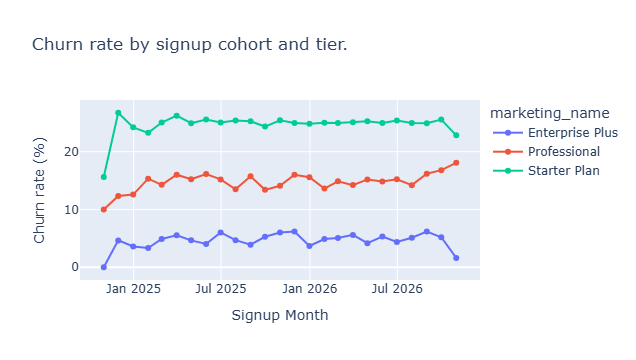

In [3]:


def churn_rate_pct(active_series):
    return (~active_series).mean() * 100

cohort_by_tier = (
    df.set_index('signup_date')
    .groupby('marketing_name')
    .resample('ME')
    .agg(
        customer_count=('customer_id', 'count'),
        churn_rate_pct=('active', churn_rate_pct)
    )
    .reset_index()
)
fig = px.line(
    cohort_by_tier,
    x='signup_date',
    y='churn_rate_pct',
    color='marketing_name',
    markers=True,
    title='Churn rate by signup cohort and tier.',
    labels = { 'signup_date': 'Signup Month',
               'churn_rate_pct': 'Churn rate (%)'}
)

fig.show()

The original cohort-by-tier analysis used unstack() to convert marketing tiers into separate columns, creating a wide-format DataFrame. This made it more difficult to reshape the data using melt() for visualization.

To simplify the analysis, I recreated the cohort-by-tier table using groupby() and reset_index(). This keeps the data in long format, with each row representing a signup cohort and marketing tier. The resulting structure makes it easier to compare churn rates across tiers and create a multi-line Plotly visualization.

## Panel 3: Monthly signup trend with smoothing.
The layered Graph Objects chart from Step 8 of the Guided Example, reproduced. Gray monthly line, steelblue rolling-3-month average overlay. Title: "Monthly signups with smoothed trend."

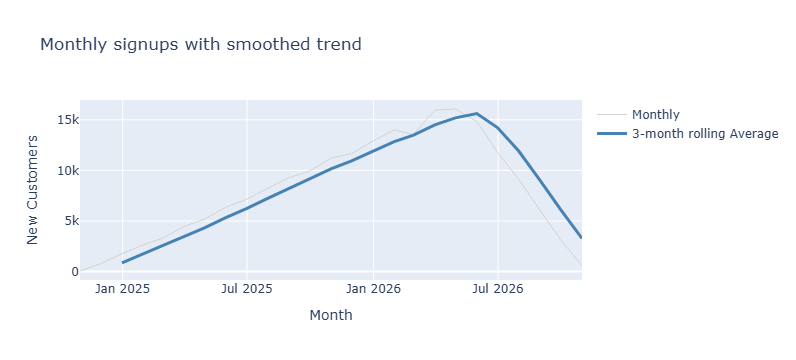

In [4]:
monthly_signups =(
    df.set_index('signup_date')
    .resample('ME')
    .size()
    .reset_index(name='signups')
)

monthly_signups['signups_smoothed']=monthly_signups['signups'].rolling(window=3).mean()

fig_signup_layered = go.Figure()

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups'],
    mode='lines',
    name='Monthly',
    line=dict(color = 'lightgray', width=1)
))

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups_smoothed'],
    mode = 'lines',
    name='3-month rolling Average',
    line=dict(color = 'steelblue', width=3)
))

fig_signup_layered.update_layout(
    title = 'Monthly signups with smoothed trend',
    xaxis_title = 'Month',
    yaxis_title = 'New Customers'
)
fig_signup_layered.show()

## Panel 4: A chart of your choice that supports the story.
Pick one chart from the lesson (bar, histogram, box plot, faceted line, or scatter) that adds something the other three panels don't. Justify the choice in one sentence in a markdown cell.

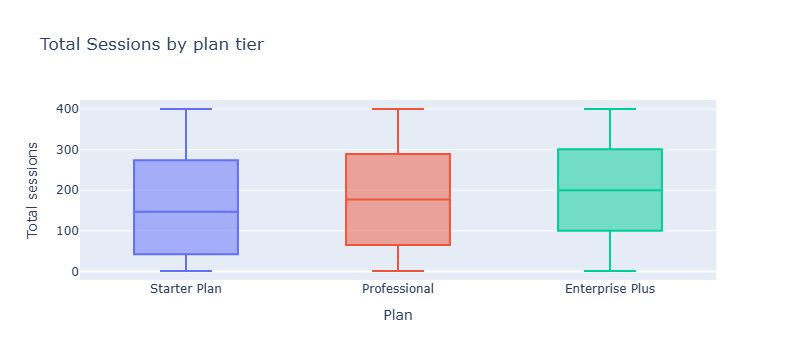

In [5]:
fig_session_box = px.box(
    df,
    x='marketing_name',
    y='total_sessions',
    color='marketing_name',
    title='Total Sessions by plan tier',
    labels={
        'marketing_name': 'Plan',
        'total_sessions': 'Total sessions'
    }
)
fig_session_box.update_layout(showlegend=False)
fig_session_box.show()

I would choose the box plot because it shows the distribution of total sessions across plan tiers, including the median, spread, and potential outliers, which the other charts don't clearly reveal.

In [6]:
deck = make_subplots(
    rows=2, cols=2,
    subplot_titles= [
        'Churn rate by signup cohort',
        'Churn rate by signup cohort and tier',
        'Monthly signups with smoothed trend',
        'Total Sessions by plan tier'
    ],
     vertical_spacing=0.10
)
# Chart 1: Overall cohort churn
deck.add_trace(
    go.Scatter(
        x=cohort_churn['signup_cohort'].astype(str),
        y=cohort_churn['churn_rate_pct'],
        mode='lines+markers',
        name='Overall churn',
        line=dict(color='firebrick')
    ),
    row=1, col=1
)

# Chart 2: Cohort churn by tier
for tier in cohort_by_tier['marketing_name'].unique():
    tier_data = cohort_by_tier[
        cohort_by_tier['marketing_name'] == tier
    ]

    deck.add_trace(
        go.Scatter(
            x=tier_data['signup_cohort'].astype(str),
            y=tier_data['churn_rate_pct'],
            mode='lines+markers',
            name=tier
        ),
        row=1, col=2
    )

# Chart 3: Monthly signups
deck.add_trace(
    go.Scatter(
        x=monthly_signups['signup_date'],
        y=monthly_signups['signups'],
        mode='lines',
        name='Monthly signups',
        line=dict(color='lightgray')
    ),
    row=2, col=1
)

deck.add_trace(
    go.Scatter(
        x=monthly_signups['signup_date'],
        y=monthly_signups['signups_smoothed'],
        mode='lines',
        name='3-month average',
        line=dict(color='steelblue', width=3)
    ),
    row=2, col=1
)

# Chart 4: Total sessions by plan tier
for tier in df['marketing_name'].unique():
    deck.add_trace(
        go.Box(
            y=df.loc[
                df['marketing_name'] == tier,
                'total_sessions'
            ],
            name=tier
        ),
        row=2, col=2
    )

# Dashboard layout
deck.update_layout(
    title='FinFlow Customer Analytics Dashboard',
    height=800,
    showlegend=True
)

deck.write_html("finflow-friday-deck-final.html")

deck.show()

KeyError: 'signup_cohort'